# Set 12 - Was funktioniert wo? Drei einfache Datensätze, eine gemeinsame Auswertung

Wir ersetzen das Bike-Beispiel durch **kontrollierte Dummy-Daten**: Sinus, Sinus plus Trend und reines Rauschen. Alle Modellfamilien werden ausschließlich über **ARIMA** gefittet.

Jeder Vergleich nutzt dieselben Trainings-, Validierungs- und Testzeiten. Die Tabellen zeigen **Daten, Modell, Prognoseprotokoll, MAE/RMSE und Verbesserung gegenüber beiden Baselines**. Alle Ergebnisse werden gezeigt, auch schlechtere.

Die Orders sind für die Erklärung vorher festgelegt. Das jeweils auf der Validierung bevorzugte Modell wird vor dem Test festgehalten. Die Testtabelle darf anschließend zeigen, ob diese Wahl dort funktioniert hat.
Die Modellwahl verwendet feste 48-Stunden-Prognosen auf der Validierung. Dieselbe Wahl wird bei beiden Testprotokollen gezeigt; sie ist deshalb nicht automatisch die beste rollende Wahl.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

kandidaten = [Path.cwd(), *Path.cwd().parents]
set_ordner = next((p for basis in kandidaten
                   for p in (basis, basis / "set12-zeitreihenanalyse")
                   if (p / "zeitreihen_tools.py").exists()), None)
if set_ordner is None:
    raise FileNotFoundError("Notebook bitte innerhalb des Kursordners starten.")
if str(set_ordner) not in sys.path:
    sys.path.insert(0, str(set_ordner))
from zeitreihen_tools import FARBEN, plot_stil, zeitachse, lag_tabelle
plot_stil()
from zeitreihen_demos import (demo_reihen, tagesmerkmale, arima_fit, feste_prognose,
    rollende_prognose, baselines, auswertung, zeitraum_plan, MODELL_SPECS)
from statsmodels.tsa.arima.model import ARIMA
from zeitreihen_demos import lesbare_tabelle


## 1. Daten und Zeiträume: Was wird wann ausgewertet?

| Dummy-Daten | Bekannte Struktur | Erwartung |
|---|---|---|
| Sinus | Niveau 50, Amplitude 8, Periode 24 h, Rauschen 0.03 | AR(2)/ARMA können die Welle fortsetzen; Vortag ist stark |
| Sinus + Trend | Zusätzlich +0.08 SE je Stunde | ARIMA mit Drift und Tagesmuster kann den Anstieg fortsetzen |
| Nur Rauschen | Niveau 50 + unabhängiges Rauschen 0.03 | Keine vorhersagbare Welle; komplexe Modelle bringen keinen sicheren Vorteil |

Training: erste 240 Stunden; Validierung: nächste 48; Test: letzte 72. **Fester Ursprung:** 72 Vorhersagen ohne neue Messungen. **Rollend:** jeweils eine Stunde, dann den neuen Messwert übernehmen.

,Daten,Abschnitt,Von,Bis,Stunden
0,Sinus,Training,2024-01-01,2024-01-10 23:00:00,240
1,Sinus,Validierung,2024-01-11,2024-01-12 23:00:00,48
2,Sinus,Test,2024-01-13,2024-01-15 23:00:00,72
3,Sinus + Trend,Training,2024-01-01,2024-01-10 23:00:00,240
4,Sinus + Trend,Validierung,2024-01-11,2024-01-12 23:00:00,48
5,Sinus + Trend,Test,2024-01-13,2024-01-15 23:00:00,72
6,Nur Rauschen,Training,2024-01-01,2024-01-10 23:00:00,240
7,Nur Rauschen,Validierung,2024-01-11,2024-01-12 23:00:00,48
8,Nur Rauschen,Test,2024-01-13,2024-01-15 23:00:00,72


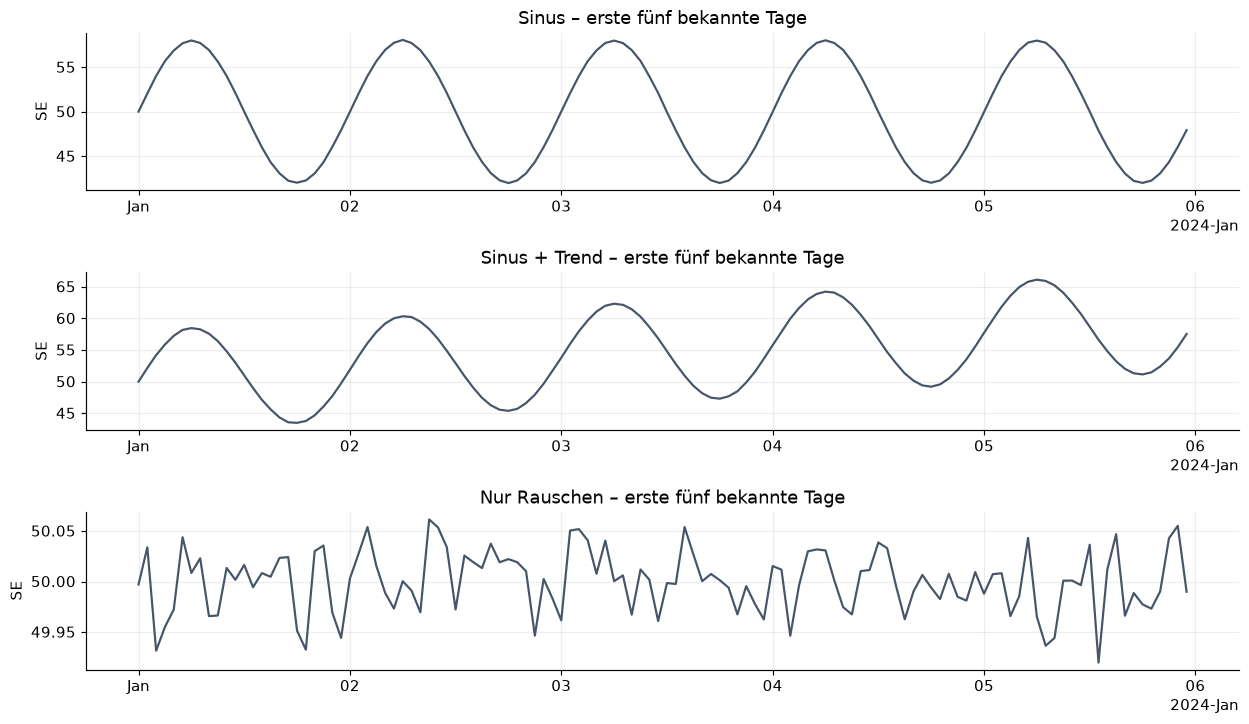

In [2]:
reihen = demo_reihen()
display(zeitraum_plan(reihen))
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
for ax, (name, y) in zip(axes, reihen.items()):
    ax.plot(y.iloc[:120], color=FARBEN["roh"])
    ax.set(title=name + " – erste fünf bekannte Tage", ylabel="SE")
    zeitachse(ax)
plt.tight_layout(); plt.show()


## 2. Welche Modelle und Baselines?

- AR(1), AR(2), MA(2), ARMA(2,1): `ARIMA` mit d=0.
- ARIMA + Tagesmuster: `ARIMA(order=(1,1,0), trend="t", exog=...)`. Die exogenen Spalten enthalten ausschließlich Sinus/Cosinus der bekannten Uhrzeit; die Koeffizienten werden gelernt.
- Letzter Wert und Vortag (24 h): unter exakt demselben Prognoseprotokoll.

Die Erzeugungsformeln helfen beim Erklären, geben dem Fit aber keine zukünftigen Messwerte. Auf dem Sinusdatensatz können AR(2)/ARMA gut sein; ein MA-Modell muss nicht jede Welle beherrschen. Auf Rauschen soll sichtbar werden, wo Vorhersagbarkeit endet.

In [3]:
val_rows = []
chosen = {}
for data_name, y in reihen.items():
    training, validation = y.iloc[:240], y.iloc[240:288]
    predictions = baselines(training, validation)
    for model_name, (order, daily) in MODELL_SPECS.items():
        fit = arima_fit(training, order, daily)
        predictions[model_name] = feste_prognose(fit, validation.index, daily).predicted_mean
    scores = auswertung(validation, predictions, data_name, "Validierung / feste 48 h")
    val_rows.append(scores)
    chosen[data_name] = scores.loc[scores.Modell.isin(MODELL_SPECS)].sort_values("MAE").iloc[0].Modell
val_scores = pd.concat(val_rows, ignore_index=True)
display(lesbare_tabelle(val_scores.sort_values(["Daten", "MAE"])))
display(pd.DataFrame([{"Daten": name, "Modellwahl vor Test": model} for name, model in chosen.items()]))


Daten,Protokoll,Modell,MAE,RMSE,vs. letzter Wert [%],vs. Vortag [%],Besser als beide
Nur Rauschen,Validierung / feste 48 h,"ARMA(2,1)",0.0189,0.0238,+6.3%,+47.1%,ja
Nur Rauschen,Validierung / feste 48 h,MA(2),0.0189,0.0238,+6.3%,+47.1%,ja
Nur Rauschen,Validierung / feste 48 h,AR(1),0.0189,0.0238,+6.2%,+47.1%,ja
Nur Rauschen,Validierung / feste 48 h,AR(2),0.0190,0.0239,+6.1%,+47.0%,ja
Nur Rauschen,Validierung / feste 48 h,ARIMA + Tagesmuster,0.0193,0.0245,+4.7%,+46.2%,ja
Nur Rauschen,Validierung / feste 48 h,Letzter Wert,0.0202,0.0257,+0.0%,+43.6%,nein
Nur Rauschen,Validierung / feste 48 h,Vortag (24 h),0.0358,0.0475,-77.2%,+0.0%,nein
Sinus,Validierung / feste 48 h,"ARMA(2,1)",0.0246,0.0307,+99.5%,+30.6%,ja
Sinus,Validierung / feste 48 h,ARIMA + Tagesmuster,0.0309,0.0391,+99.4%,+12.8%,ja
Sinus,Validierung / feste 48 h,AR(2),0.0317,0.0419,+99.4%,+10.7%,ja


,Daten,Modellwahl vor Test
0,Sinus,"ARMA(2,1)"
1,Sinus + Trend,ARIMA + Tagesmuster
2,Nur Rauschen,"ARMA(2,1)"


## 3. Die vollständige Testauswertung

**Positive Prozentwerte = weniger MAE als die Baseline. Negative = mehr Fehler.** „Besser als beide“ verlangt einen geringeren MAE als sowohl letzter Wert als auch Vortag. MAE und RMSE sind in derselben Einheit SE.

Die Tabellen werden pro Datensatz getrennt ausgegeben, damit sie lesbar bleiben. Die Zeittabelle oben legt fest, wann trainiert und getestet wurde. Beide Protokolle dürfen nur innerhalb ihres jeweiligen Informationsstands verglichen werden.

In [4]:
test_rows = []
all_predictions = {}
for data_name, y in reihen.items():
    history, test = y.iloc[:288], y.iloc[288:]
    fixed = baselines(history, test)
    rolling = baselines(history, test, rollend=True, volle_reihe=y)
    for model_name, (order, daily) in MODELL_SPECS.items():
        fit = arima_fit(history, order, daily)
        fixed[model_name] = feste_prognose(fit, test.index, daily).predicted_mean
        rolling[model_name] = rollende_prognose(fit, test, daily)
    for protocol, predictions in [("Feste 72 h", fixed), ("Rollende 1 h", rolling)]:
        scores = auswertung(test, predictions, data_name, protocol)
        test_rows.append(scores)
        all_predictions[data_name, protocol] = predictions
    print("DATENSATZ:", data_name, "| Test:", test.index[0], "bis", test.index[-1])
    display(lesbare_tabelle(pd.concat(test_rows[-2:], ignore_index=True).sort_values(["Protokoll", "MAE"]).drop(columns="Daten")))
test_scores = pd.concat(test_rows, ignore_index=True)


DATENSATZ: Sinus | Test: 2024-01-13 00:00:00 bis 2024-01-15 23:00:00


Protokoll,Modell,MAE,RMSE,vs. letzter Wert [%],vs. Vortag [%],Besser als beide
Feste 72 h,ARIMA + Tagesmuster,0.0239,0.0306,+99.5%,+26.0%,ja
Feste 72 h,"ARMA(2,1)",0.0318,0.0372,+99.4%,+1.5%,ja
Feste 72 h,Vortag (24 h),0.0323,0.0418,+99.4%,+0.0%,nein
Feste 72 h,AR(2),0.0948,0.1132,+98.2%,-193.8%,nein
Feste 72 h,MA(2),5.0800,5.6564,+3.0%,-15647.3%,nein
Feste 72 h,Letzter Wert,5.2381,6.0217,+0.0%,-16137.4%,nein
Feste 72 h,AR(1),5.2767,5.8586,-0.7%,-16257.0%,nein
Rollende 1 h,ARIMA + Tagesmuster,0.0286,0.0379,+97.9%,+18.4%,ja
Rollende 1 h,Vortag (24 h),0.0350,0.0430,+97.4%,+0.0%,nein
Rollende 1 h,"ARMA(2,1)",0.0371,0.0459,+97.2%,-5.9%,nein


DATENSATZ: Sinus + Trend | Test: 2024-01-13 00:00:00 bis 2024-01-15 23:00:00


Protokoll,Modell,MAE,RMSE,vs. letzter Wert [%],vs. Vortag [%],Besser als beide
Feste 72 h,ARIMA + Tagesmuster,0.0356,0.0428,+99.4%,+99.1%,ja
Feste 72 h,Vortag (24 h),3.8374,4.1448,+36.1%,+0.0%,nein
Feste 72 h,Letzter Wert,6.0064,7.4408,+0.0%,-56.5%,nein
Feste 72 h,AR(1),7.4999,9.0462,-24.9%,-95.4%,nein
Feste 72 h,"ARMA(2,1)",13.7541,16.1603,-129.0%,-258.4%,nein
Feste 72 h,AR(2),14.1123,16.5817,-135.0%,-267.8%,nein
Feste 72 h,MA(2),14.1323,15.2090,-135.3%,-268.3%,nein
Rollende 1 h,ARIMA + Tagesmuster,0.0299,0.0356,+97.8%,+98.4%,ja
Rollende 1 h,"ARMA(2,1)",0.2773,0.3205,+79.2%,+85.5%,ja
Rollende 1 h,AR(2),0.4099,0.4778,+69.3%,+78.6%,ja


DATENSATZ: Nur Rauschen | Test: 2024-01-13 00:00:00 bis 2024-01-15 23:00:00


Protokoll,Modell,MAE,RMSE,vs. letzter Wert [%],vs. Vortag [%],Besser als beide
Feste 72 h,"ARMA(2,1)",0.0228,0.0290,+8.9%,+14.2%,ja
Feste 72 h,AR(1),0.0229,0.0291,+8.6%,+13.9%,ja
Feste 72 h,MA(2),0.0229,0.0291,+8.6%,+13.9%,ja
Feste 72 h,AR(2),0.0229,0.0291,+8.5%,+13.9%,ja
Feste 72 h,ARIMA + Tagesmuster,0.0231,0.0293,+7.7%,+13.1%,ja
Feste 72 h,Letzter Wert,0.0250,0.0315,+0.0%,+5.9%,nein
Feste 72 h,Vortag (24 h),0.0266,0.0344,-6.2%,+0.0%,nein
Rollende 1 h,AR(1),0.0232,0.0295,+30.9%,+14.9%,ja
Rollende 1 h,AR(2),0.0234,0.0297,+30.4%,+14.3%,ja
Rollende 1 h,MA(2),0.0236,0.0299,+29.9%,+13.7%,ja


## 4. Die Wellen im direkten Vergleich

Die nach Validierung ausgewählten Modelle werden hier **unverändert** gezeigt. Links liegt der letzte Wert weit daneben; der Vortag ist ein sinnvoller zusätzlicher Vergleich. Unter den Kurven zeigt der kumulierte Fehlergewinn, wann sich das Modell gegenüber der stärkeren Baseline verbessert: oberhalb von 0 bedeutet weniger aufsummierten absoluten Fehler.

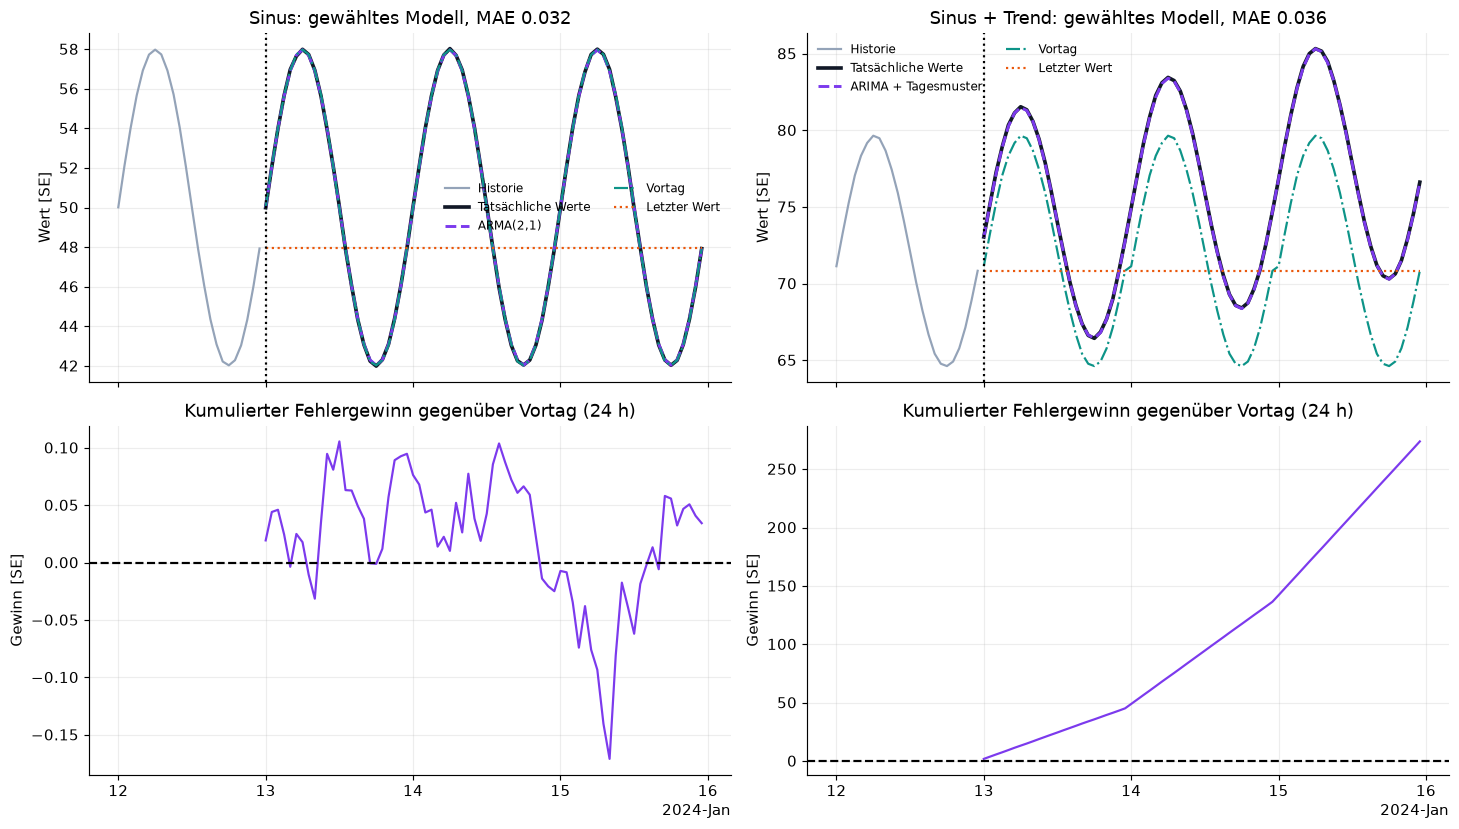

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col")
for col, data_name in enumerate(["Sinus", "Sinus + Trend"]):
    y = reihen[data_name]; test = y.iloc[288:]
    model_name = chosen[data_name]
    predictions = all_predictions[data_name, "Feste 72 h"]
    ax = axes[0, col]
    ax.plot(y.iloc[264:288], color="#94a3b8", label="Historie")
    ax.plot(test, color="#111827", lw=2.5, label="Tatsächliche Werte")
    ax.plot(predictions[model_name], color=FARBEN["prognose"], ls="--", lw=2, label=model_name)
    ax.plot(predictions["Vortag (24 h)"], color=FARBEN["saison"], ls="-.", label="Vortag")
    ax.plot(predictions["Letzter Wert"], color=FARBEN["trend"], ls=":", label="Letzter Wert")
    ax.axvline(test.index[0], color="black", ls=":")
    model_mae = (test-predictions[model_name]).abs().mean()
    ax.set(title=f"{data_name}: gewähltes Modell, MAE {model_mae:.3f}", ylabel="Wert [SE]")
    ax.legend(fontsize=8, ncol=2)
    baseline_name = min(["Letzter Wert", "Vortag (24 h)"], key=lambda n: (test-predictions[n]).abs().mean())
    gain = ((test-predictions[baseline_name]).abs() - (test-predictions[model_name]).abs()).cumsum()
    axes[1, col].plot(gain, color=FARBEN["prognose"])
    axes[1, col].axhline(0, color="black", ls="--")
    axes[1, col].set(title="Kumulierter Fehlergewinn gegenüber " + baseline_name, ylabel="Gewinn [SE]")
    zeitachse(axes[1, col])
plt.tight_layout(); plt.show()


## 5. Übersicht: Was war wo und wann besser?

Die folgende kompakte Tabelle nimmt pro Datensatz und Protokoll das **vor dem Test gewählte Modell** und die im Test stärkere Baseline. „MAE-Gewinn“ ist die prozentuale Verbesserung des Modells gegenüber dieser Baseline. Die vollständige Tabelle oben enthält weiterhin alle Kandidaten.

Darunter wird der feste 72-Stunden-Test in drei Tage aufgeteilt. Das macht sichtbar, an welchen Tagen der Vorteil bestand; die Tagesergebnisse führen zu keiner nachträglichen Modellwahl.

In [6]:
summary_rows, day_rows = [], []
for data_name, y in reihen.items():
    test = y.iloc[288:]
    for protocol in ["Feste 72 h", "Rollende 1 h"]:
        predictions = all_predictions[data_name, protocol]
        model_name = chosen[data_name]
        base = min(["Letzter Wert", "Vortag (24 h)"], key=lambda n: (test-predictions[n]).abs().mean())
        model_mae = (test-predictions[model_name]).abs().mean()
        base_mae = (test-predictions[base]).abs().mean()
        summary_rows.append({"Daten": data_name, "Protokoll": protocol, "Gewähltes Modell": model_name,
                             "Stärkere Baseline": base, "Modell-MAE": model_mae, "Baseline-MAE": base_mae,
                             "MAE-Gewinn [%]": 100*(1-model_mae/base_mae),
                             "Befund": "Modell besser" if model_mae<base_mae else "Baseline besser"})
        if protocol == "Feste 72 h":
            for date, block in test.groupby(test.index.date):
                model_error=(block-predictions[model_name].loc[block.index]).abs().mean()
                baseline_error=(block-predictions[base].loc[block.index]).abs().mean()
                day_rows.append({"Daten": data_name, "Testtag": str(date), "Modell": model_name,
                                 "Modell-MAE": model_error, "Baseline-MAE": baseline_error,
                                 "MAE-Gewinn [%]": 100*(1-model_error/baseline_error)})
summary = pd.DataFrame(summary_rows)
daily_scores = pd.DataFrame(day_rows)
display(lesbare_tabelle(summary))
display(lesbare_tabelle(daily_scores))
# Genau die im Notebook gezeigten Zahlen als weiterverwendbare Tabellen speichern.
export = test_scores.copy()
export["Training bis"] = reihen["Sinus"].index[287]
export["Test von"] = reihen["Sinus"].index[288]
export["Test bis"] = reihen["Sinus"].index[-1]
export.to_csv(set_ordner / "auswertung_set12.csv", index=False, encoding="utf-8-sig")
summary.to_csv(set_ordner / "auswertung_set12_uebersicht.csv", index=False, encoding="utf-8-sig")


Daten,Protokoll,Gewähltes Modell,Stärkere Baseline,Modell-MAE,Baseline-MAE,MAE-Gewinn [%],Befund
Sinus,Feste 72 h,"ARMA(2,1)",Vortag (24 h),0.0318,0.0323,+1.5%,Modell besser
Sinus,Rollende 1 h,"ARMA(2,1)",Vortag (24 h),0.0371,0.0350,-5.9%,Baseline besser
Sinus + Trend,Feste 72 h,ARIMA + Tagesmuster,Vortag (24 h),0.0356,3.8374,+99.1%,Modell besser
Sinus + Trend,Rollende 1 h,ARIMA + Tagesmuster,Letzter Wert,0.0299,1.3348,+97.8%,Modell besser
Nur Rauschen,Feste 72 h,"ARMA(2,1)",Letzter Wert,0.0228,0.0250,+8.9%,Modell besser
Nur Rauschen,Rollende 1 h,"ARMA(2,1)",Vortag (24 h),0.0407,0.0273,-49.0%,Baseline besser


Daten,Testtag,Modell,Modell-MAE,Baseline-MAE,MAE-Gewinn [%]
Sinus,2024-01-13,"ARMA(2,1)",0.0282,0.0321,+12.3%
Sinus,2024-01-14,"ARMA(2,1)",0.0358,0.0308,-16.2%
Sinus,2024-01-15,"ARMA(2,1)",0.0314,0.0338,+7.3%
Sinus + Trend,2024-01-13,ARIMA + Tagesmuster,0.0352,1.9161,+98.2%
Sinus + Trend,2024-01-14,ARIMA + Tagesmuster,0.0406,3.8446,+98.9%
Sinus + Trend,2024-01-15,ARIMA + Tagesmuster,0.0310,5.7515,+99.5%
Nur Rauschen,2024-01-13,"ARMA(2,1)",0.0225,0.0249,+9.6%
Nur Rauschen,2024-01-14,"ARMA(2,1)",0.0228,0.0241,+5.7%
Nur Rauschen,2024-01-15,"ARMA(2,1)",0.0231,0.0260,+11.1%


## Einordnung und Aufgaben

Die sehr sauberen Daten wurden bewusst zum Erklären gewählt. Ein passendes Modell kann hier die Welle und den Trend sichtbar fortsetzen. Reines Rauschen enthält keine vorhersagbaren zukünftigen Schocks. Die Tabellen zeigen deshalb auch Baseline-Siege.

1. Wo reicht AR(2), und wo hilft Differenzierung plus Tagesmuster?
2. Warum kann MA(2) die Tageswelle nicht über drei Tage fortsetzen?
3. Vergleiche denselben Datensatz unter festen 72 h und rollender 1 h.
4. Welche Baseline ist wann stark? Nutze die Testtag-Tabelle.
5. Erhöhe das Rauschen in `zeitreihen_demos.py`. Wie verändern sich Kurven und Fehler?

Die CSV-Dateien enthalten die gleichen Ergebnisse wie die ausgeführten Tabellen. Kein Modell erhält zukünftige Zielwerte.